In [ ]:
! pip install pandas numpy matplotlib seaborn scikit-learn plotly streamlit

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold,cross_validate
from sklearn.preprocessing import StandardScaler

In [4]:
df = pd.read_csv('Hr promotion.csv')
df.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  awards_won?           54808 non-null  int64  
 11  avg_training_score    54808 non-null  int64  
 12  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 5.4+ MB


In [6]:
df.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,50684.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.329256,5.865512,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.259993,4.265094,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,99.000000,1.000000


In [7]:
df.isna().sum()

employee_id                0
department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64

In [8]:
df.dropna(inplace=True)

In [9]:
df.isna().sum()

employee_id             0
department              0
region                  0
education               0
gender                  0
recruitment_channel     0
no_of_trainings         0
age                     0
previous_year_rating    0
length_of_service       0
awards_won?             0
avg_training_score      0
is_promoted             0
dtype: int64

In [10]:
df = df.drop(['employee_id'],axis=1)

In [11]:
df2 = df.copy()

<Axes: xlabel='is_promoted', ylabel='count'>

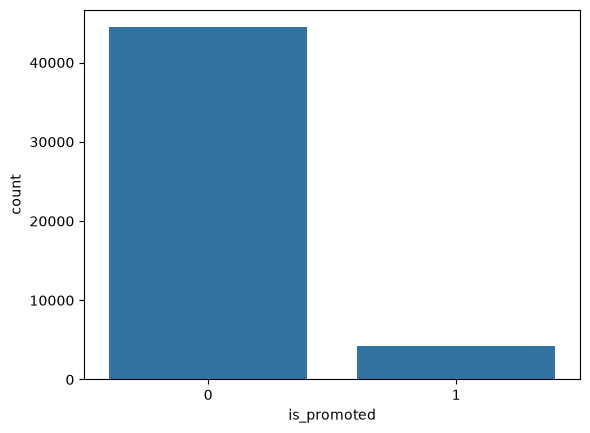

In [12]:
sns.countplot(x='is_promoted',data=df)

<Axes: xlabel='department', ylabel='count'>

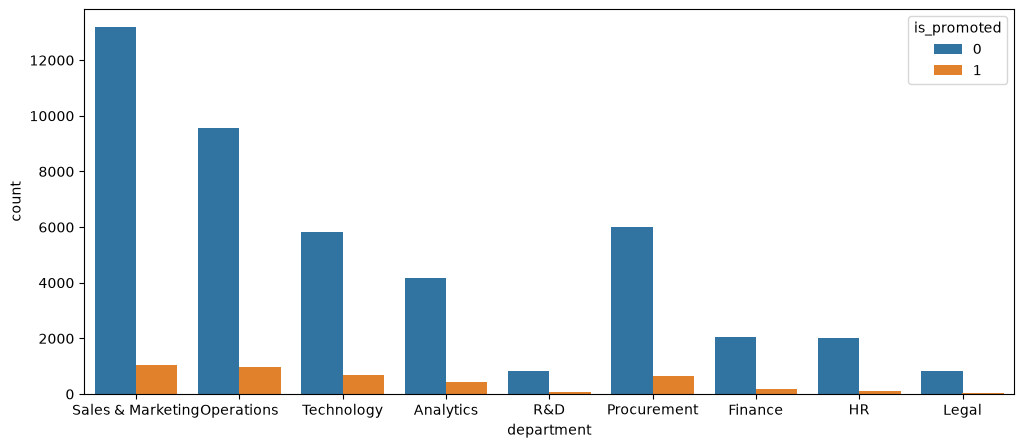

In [16]:
plt.figure(figsize=(12,5))
sns.countplot(x='department',hue='is_promoted',data=df)


In [17]:
X = df.drop(['is_promoted'],axis=1)
y = df['is_promoted']

In [19]:
X = pd.get_dummies(X,drop_first=True, dtype=int)

In [20]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [21]:
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.transform(x_test)

In [22]:
lr = LogisticRegression()
lr.fit(x_train_scaled,y_train)
y_pred = lr.predict(x_test_scaled)
print("classification report for training", classification_report(y_train,lr.predict(x_train_scaled)))
print("classification report for testing", classification_report(y_test,y_pred))

classification report for training               precision    recall  f1-score   support

           0       0.94      1.00      0.97     35563
           1       0.95      0.30      0.45      3365

    accuracy                           0.94     38928
   macro avg       0.94      0.65      0.71     38928
weighted avg       0.94      0.94      0.92     38928

classification report for testing               precision    recall  f1-score   support

           0       0.94      1.00      0.97      8865
           1       0.96      0.30      0.46       867

    accuracy                           0.94      9732
   macro avg       0.95      0.65      0.71      9732
weighted avg       0.94      0.94      0.92      9732



In [26]:
rf = RandomForestClassifier(max_depth=5)
rf.fit(x_train_scaled,y_train)
y_pred_rf = rf.predict(x_test_scaled)
print("classification report for training \n", classification_report(y_train,rf.predict(x_train_scaled)))
print("classification report for testing \n", classification_report(y_test,y_pred_rf))

classification report for training 
               precision    recall  f1-score   support

           0       0.92      1.00      0.96     35563
           1       1.00      0.07      0.12      3365

    accuracy                           0.92     38928
   macro avg       0.96      0.53      0.54     38928
weighted avg       0.93      0.92      0.89     38928

classification report for testing 
               precision    recall  f1-score   support

           0       0.92      1.00      0.96      8865
           1       1.00      0.07      0.12       867

    accuracy                           0.92      9732
   macro avg       0.96      0.53      0.54      9732
weighted avg       0.92      0.92      0.88      9732



In [28]:
cv = KFold(n_splits=5,shuffle=True,random_state=42)
scores = cross_validate(rf,X,y,cv=cv,scoring=['accuracy','precision','recall','f1'])
scores_df = pd.DataFrame(scores)
scores_df

,fit_time,score_time,test_accuracy,test_precision,test_recall,test_f1
0,1.139048,0.040269,0.915331,1.000000,0.049596,0.094505
1,1.159843,0.045656,0.914098,1.000000,0.040184,0.077263
2,1.504528,0.046336,0.918311,1.000000,0.046763,0.089347
3,1.115320,0.040740,0.919030,0.981481,0.063095,0.118568
4,1.050664,0.025264,0.919955,1.000000,0.050000,0.095238


In [29]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(rf,param_grid={'max_depth':[3,5,7,9]},cv=cv,scoring='f1')
grid.fit(X,y)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(max_depth=5),
             param_grid={'max_depth': [3, 5, 7, 9]}, scoring='f1')

In [30]:
grid.best_params_

{'max_depth': 9}

In [32]:
rf = RandomForestClassifier(max_depth=grid.best_params_['max_depth'])
rf.fit(x_train_scaled, y_train)
rf_pred = rf.predict(x_test_scaled)
print("classification report for training \n", classification_report(y_train,rf.predict(x_train_scaled)))
print("classification report for testing \n", classification_report(y_test,rf_pred))

classification report for training 
               precision    recall  f1-score   support

           0       0.92      1.00      0.96     35563
           1       0.99      0.13      0.23      3365

    accuracy                           0.92     38928
   macro avg       0.96      0.56      0.59     38928
weighted avg       0.93      0.92      0.90     38928

classification report for testing 
               precision    recall  f1-score   support

           0       0.92      1.00      0.96      8865
           1       0.97      0.13      0.23       867

    accuracy                           0.92      9732
   macro avg       0.95      0.56      0.59      9732
weighted avg       0.93      0.92      0.89      9732



In [33]:
df

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0
...,...,...,...,...,...,...,...,...,...,...,...,...
54802,Sales & Marketing,region_14,Bachelor's,m,other,2,31,1.0,2,0,49,0
54803,Technology,region_14,Bachelor's,m,sourcing,1,48,3.0,17,0,78,0
54804,Operations,region_27,Master's & above,f,other,1,37,2.0,6,0,56,0
54805,Analytics,region_1,Bachelor's,m,other,1,27,5.0,3,0,79,0


In [34]:
X = df.drop(['is_promoted'],axis=1)
y = df['is_promoted']

In [35]:
numerical_features = X.select_dtypes(include=['int64','float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

In [36]:
numerical_features

Index(['no_of_trainings', 'age', 'previous_year_rating', 'length_of_service',
       'awards_won?', 'avg_training_score'],
      dtype='object')

In [37]:
categorical_features

Index(['department', 'region', 'education', 'gender', 'recruitment_channel'], dtype='object')

In [38]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer

numerical_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler(with_mean=False))
])



In [40]:
categorical_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore')) 
    ])

In [41]:
categorical_transformer

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])

In [42]:
column_transformer = ColumnTransformer(transformers=[
    ('num',numerical_transformer,numerical_features),
    ('cat',categorical_transformer,categorical_features)
], remainder='passthrough')

In [43]:
column_transformer

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['no_of_trainings', 'age', 'previous_year_rating', 'length_of_service',
       'awards_won?', 'avg_training_score'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['department', 'region', 'education', 'gender', 'recruitment_channel'], dtype='object'))])

In [44]:
rf = RandomForestClassifier(max_depth=grid.best_params_['max_depth'])
pipeline = Pipeline(steps=[
    ('preprocessor',column_transformer),
    ('classifier', rf)
])

In [45]:
pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['no_of_trainings', 'age', 'previous_year_rating', 'length_of_service',
       'awards_won?', 'avg_training_score'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['department', 'region', 'education', 'gender', 'recruitment_channel'], dtype='object'))])),
                ('classifier', RandomForestClassifier(max_depth=9))])

In [46]:
pipeline.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['no_of_trainings', 'age', 'previous_year_rating', 'length_of_service',
       'awards_won?', 'avg_training_score'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['department', 'region', 'education', 'gender', 'recruitment_channel'], dtype='object'))])),
                ('classifier', RandomForestClassifier(max_depth=9))])

In [47]:
y_pred = pipeline.predict(x_test)

In [48]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(9732,))

In [49]:
import joblib
joblib.dump(pipeline,'hr_model.pkl')

['hr_model.pkl']

In [51]:
x_train

,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score
28596,Sales & Marketing,region_25,Bachelor's,m,other,1,30,3.0,6,0,51
18945,Operations,region_4,Master's & above,m,sourcing,1,37,5.0,10,0,60
47016,Operations,region_23,Master's & above,m,other,1,38,3.0,9,0,57
52765,Procurement,region_22,Bachelor's,m,sourcing,9,27,3.0,4,0,75
13423,Operations,region_22,Bachelor's,m,other,1,29,2.0,2,0,59
...,...,...,...,...,...,...,...,...,...,...,...
12739,Procurement,region_15,Bachelor's,f,other,1,41,3.0,12,0,69
50417,Technology,region_28,Master's & above,m,sourcing,1,36,4.0,9,0,78
43003,Technology,region_13,Master's & above,m,other,1,30,4.0,3,0,82
985,Sales & Marketing,region_22,Bachelor's,m,referred,1,29,3.0,2,0,55


In [52]:
classifier = joblib.load('hr_model.pkl')
prediction = classifier.predict(pd.DataFrame({
    'department':['Sales & Marketing'],
    'region':['region_1'],
    'education':['Bachelor\'s'],
    'gender':['m'],
    'recruitment_channel':['sourcing'],
    'no_of_trainings':[2],
    'age':[35],
    'previous_year_rating':[4],
    'length_of_service':[10],
    'awards_won?':[1],
    'avg_training_score':[85]

}))
prediction

array([1])

In [55]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import numpy as np
import plotly.express as px


classifier = joblib.load('hr_model.pkl')

st.title('HR Prediction App')
st.write('This app predicts whether an employee will be promoted or not based on their features.')
df = pd.read_csv('Hr promotion.csv')
def predict_promotion(department, region, education, gender, recruitment_channel, no_of_trainings, age, previous_year_rating, length_of_service, awards_won, avg_training_score):
    input_data = pd.DataFrame({
        'department': [department],
        'region': [region],
        'education': [education],
        'gender': [gender],
        'recruitment_channel': [recruitment_channel],
        'no_of_trainings': [no_of_trainings],
        'age': [age],
        'previous_year_rating': [previous_year_rating],
        'length_of_service': [length_of_service],
        'awards_won?': [awards_won],
        'avg_training_score': [avg_training_score]
    })
    label = ['Not Promoted', 'Promoted']
    prediction = classifier.predict(input_data)
    return label[prediction[0]]


def main():
    department = st.selectbox('Department', df['department'].unique())
    region = st.selectbox('Region', df['region'].unique())
    education = st.selectbox('Education', df['education'].unique())
    gender = st.selectbox('Gender', df['gender'].unique())
    recruitment_channel = st.selectbox('Recruitment Channel', df['recruitment_channel'].unique())
    no_of_trainings = st.number_input('Number of Trainings', min_value=0, max_value=10, value=0)
    age = st.number_input('Age', min_value=18, max_value=65, value=30)
    previous_year_rating = st.number_input('Previous Year Rating', min_value=1, max_value=5, value=3)
    length_of_service = st.number_input('Length of Service (years)', min_value=0, max_value=40, value=5)
    awards_won = st.selectbox('Awards Won?', [0, 1])
    avg_training_score = st.number_input('Average Training Score', min_value=0, max_value=100, value=50)

    if st.button('Predict Promotion'):
        result = predict_promotion(department, region, education, gender, recruitment_channel,
                                   no_of_trainings, age, previous_year_rating,
                                   length_of_service, awards_won, avg_training_score)
        st.success(f'The employee is predicted to be: {result}')

if __name__ == '__main__':
    main()           

Overwriting app.py
